# 1. Portada e introducción
## Microproyecto 1 — Generación de Bocetos (Sketch-RNN)
## Maestría en Inteligencia Artificial (MAIA) — Universidad de los Andes
### Curso: Modelos Avanzados de Procesamiento de Lenguaje Natural (MAPLN)

---

### Información General
* **Equipo de Trabajo:** Equipo 21
* **Integrantes:**
  1. Juan Javier Valera Mejias
  2. Juan David Villalba Guavita
  3. Juan Felipe Rodriguez Granados
  4. Leidy Dayana Vega Medina
  5. Cesar Steven Leal Perez
* **Categoría Seleccionada:** `cat` (gatos) — Dataset *Quick, Draw!*
* **Entorno de Ejecución:** Compatible con Google Colab (CPU / GPU CUDA) y entornos locales Jupyter.

---

### 1. Resumen Ejecutivo del Proyecto
El objetivo del presente microproyecto consiste en implementar, entrenar y evaluar una red neuronal recurrente autorregresiva de tipo **Sketch-RNN** capaz de sintetizar de manera autónoma bocetos vectoriales correspondientes a la categoría seleccionada (`cat`). 

A diferencia de las imágenes matriciales bidimensionales convencionales, los bocetos vectoriales se modelan matemáticamente como trayectorias temporales continuas y discretas. En cada instante $t$, el lápiz ejecuta un desplazamiento espacial bidimensional $(\Delta x, \Delta y)$ acompañado por un estado de transición del trazo ($pen\_state$). Este paradigma introduce retos esenciales de aprendizaje profundo:
1. **Modelado Secuencial con Múltiples Salidas (Multi-Task Learning):** El modelo debe aproximar de forma simultánea dos variables numéricas continuas mediante regresión euclidiana $(\Delta x_t, \Delta y_t)$ y una variable categórica discreta de tres estados ($pen\_state_t$) mediante clasificación probabilística.
2. **Función de Pérdida Compuesta:** Combina Error Cuadrático Medio (MSE) para los desplazamientos y Entropía Cruzada Categórica (*Categorical Cross-Entropy*) ponderada para los estados del lápiz.
3. **Gestión de Longitudes Variables y Enmascaramiento (*Masking*):** Dado que los bocetos poseen diferente número de puntos, se implementa una longitud fija de 200 pasos con relleno (*padding*). Es mandatorio enmascarar estrictamente las pérdidas y métricas para que los puntos artificiales no distorsionen el entrenamiento ni la evaluación.
4. **Generación Autorregresiva:** Síntesis iterativa punto a punto a partir de un estado semilla inicial, con detención dinámica guiada por el cabezal de clasificación o límite temporal.

---

### 2. Explicación Detallada de la Arquitectura Seleccionada
La arquitectura desarrollada se fundamenta en un **Backbone Recurrente LSTM Multi-Capa con Cabezales Desacoplados de Regresión y Clasificación**:

1. **Vector de Entrada ($t-1$):** Cada punto se codifica en representación *stroke-5*: $[\Delta x_{\text{norm}}, \Delta y_{\text{norm}}, p_1, p_2, p_3]$, de dimensión $D=5$. Las coordenadas están normalizadas por la desviación estándar global del conjunto de entrenamiento, y los tres últimos valores corresponden a la codificación *one-hot* del estado del lápiz.
2. **Backbone Recurrente (LSTM):** Una red de celdas LSTM apiladas de 2 capas con un tamaño de estado oculto de $H=256$ dimensiones y una tasa de regularización por *Dropout* de $0.20$. La celda LSTM mantiene una memoria persistente a corto y largo plazo ($(h_t, c_t)$), permitiendo correlacionar trazos lejanos en el dibujo (por ejemplo, cerrar la silueta de la cabeza o ubicar las orejas y bigotes del gato simétricamente).
3. **Cabezal de Regresión (Continuous Head):** Proyección lineal $\text{Linear}(256 \to 2)$ que emite las predicciones continuas $(\Delta \hat{x}_t, \Delta \hat{y}_t)$. Se entrena minimizando el MSE sobre los puntos reales.
4. **Cabezal de Clasificación (Discrete Head):** Proyección lineal $\text{Linear}(256 \to 3)$ que emite los *logits* no normalizados sobre los tres estados posibles:
   * **Estado 0 ($p_1$):** Lápiz tocando el papel (continuación del trazo).
   * **Estado 1 ($p_2$):** Lápiz levantado al final del trazo actual (inicio de un nuevo trazo en el siguiente punto).
   * **Estado 2 ($p_3$):** Fin definitivo del dibujo (condición de parada de la secuencia).
5. **Justificación de la Selección:** 
   * La estructura de cabezales desacoplados previene el gradiente destructivo que ocurriría si se forzara a una única capa densa a proyectar salidas de dominios numéricos y probabilísticos dispares.
   * La LSTM ofrece una dinámica de compuertas superior a una RNN simple frente a secuencias de hasta 200 pasos temporales, mitigando de raíz el fenómeno de desvanecimiento o explosión del gradiente.
   * El desacoplamiento de la función de pérdida con soporte de máscara booleana garantiza que el modelo aprenda exclusivamente la dinámica biomecánica del trazo humano sin sesgarse por los tokens nulos de relleno.

---

### 3. Diagrama de la Arquitectura del Sistema
A continuación se renderiza el diagrama formal de la arquitectura del modelo implementado:


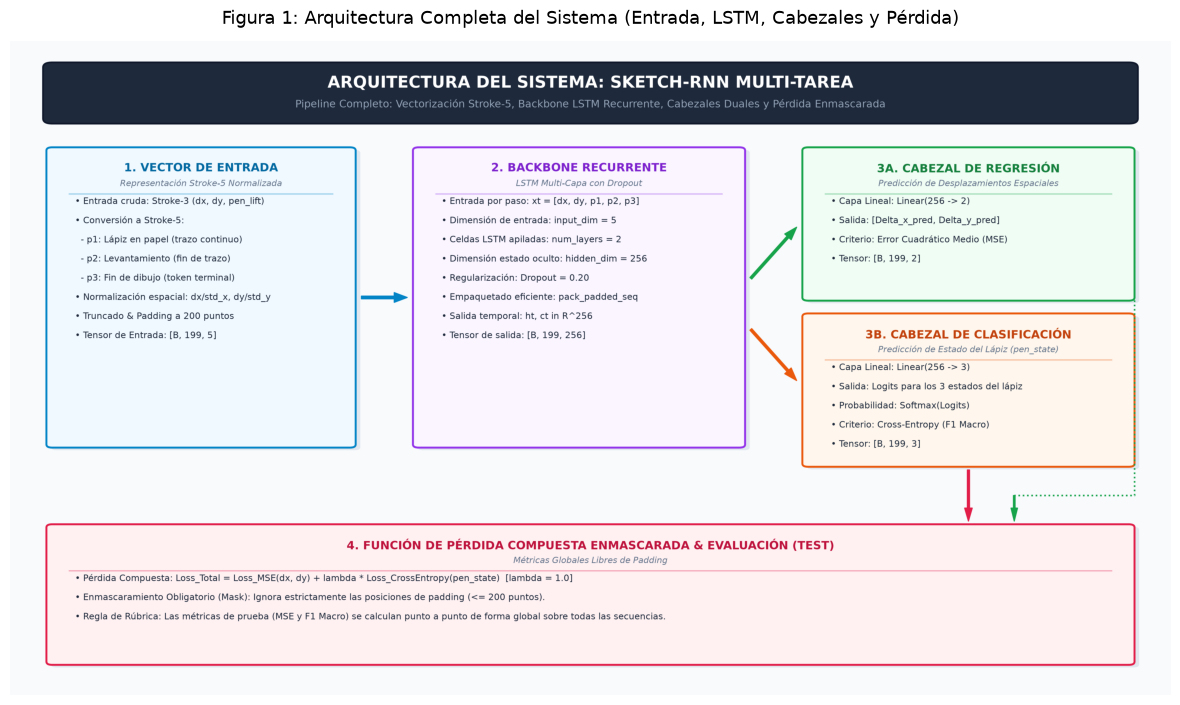

In [1]:
# Renderizado y verificación del diagrama de arquitectura dentro del notebook
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as patches

diagram_path = "diagrama_arquitectura.png"

# Si el archivo no existe en el entorno activo (ej. sesión limpia en Colab), se genera de forma determinista
if not os.path.exists(diagram_path):
    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig = plt.figure(figsize=(15, 8.5), dpi=300)
    ax = fig.add_subplot(111)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis('off')

    fig.patch.set_facecolor('#F8FAFC')
    ax.set_facecolor('#F8FAFC')

    header_box = patches.FancyBboxPatch((3, 89), 94, 8, boxstyle='round,pad=0.8', facecolor='#1E293B', edgecolor='#0F172A', linewidth=1.5)
    ax.add_patch(header_box)
    ax.text(50, 94.5, 'ARQUITECTURA DEL SISTEMA: SKETCH-RNN MULTI-TAREA', ha='center', va='center', fontsize=15, fontweight='bold', color='#FFFFFF')
    ax.text(50, 91.2, 'Pipeline Completo: Vectorización Stroke-5, Backbone LSTM Recurrente, Cabezales Duales y Pérdida Enmascarada', ha='center', va='center', fontsize=9.5, color='#94A3B8')

    def draw_block(x, y, w, h, title, subtitle, items, bg_color, border_color, title_color='#0F172A'):
        shadow = patches.FancyBboxPatch((x+0.4, y-0.4), w, h, boxstyle='round,pad=0.5', facecolor='#CBD5E1', edgecolor='none', alpha=0.5)
        ax.add_patch(shadow)
        card = patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.5', facecolor=bg_color, edgecolor=border_color, linewidth=1.8)
        ax.add_patch(card)
        ax.text(x + w/2, y + h - 2.8, title, ha='center', va='center', fontsize=10.5, fontweight='bold', color=title_color)
        if subtitle:
            ax.text(x + w/2, y + h - 5.2, subtitle, ha='center', va='center', fontsize=8, style='italic', color='#64748B')
            start_y = y + h - 8.0
        else:
            start_y = y + h - 5.5
        ax.plot([x + 1.5, x + w - 1.5], [start_y + 1.2, start_y + 1.2], color=border_color, alpha=0.4, linewidth=1)
        for i, it in enumerate(items):
            ax.text(x + 2.0, start_y - (i * 3.0), it, ha='left', va='center', fontsize=8.2, color='#1E293B')

    items_in = [
        '• Entrada cruda: Stroke-3 (dx, dy, pen_lift)',
        '• Conversión a Stroke-5:',
        '  - p1: Lápiz en papel (trazo continuo)',
        '  - p2: Levantamiento (fin de trazo)',
        '  - p3: Fin de dibujo (token terminal)',
        '• Normalización espacial: dx/std_x, dy/std_y',
        '• Truncado & Padding a 200 puntos',
        '• Tensor de Entrada: [B, 199, 5]'
    ]
    draw_block(3, 38, 26, 46, '1. VECTOR DE ENTRADA', 'Representación Stroke-5 Normalizada', items_in, '#F0F9FF', '#0284C7', '#0369A1')

    ax.annotate('', xy=(34, 61), xytext=(30, 61), arrowprops=dict(facecolor='#0284C7', edgecolor='#0284C7', width=2.5, headwidth=9))

    items_lstm = [
        '• Entrada por paso: xt = [dx, dy, p1, p2, p3]',
        '• Dimensión de entrada: input_dim = 5',
        '• Celdas LSTM apiladas: num_layers = 2',
        '• Dimensión estado oculto: hidden_dim = 256',
        '• Regularización: Dropout = 0.20',
        '• Empaquetado eficiente: pack_padded_seq',
        '• Salida temporal: ht, ct in R^256',
        '• Tensor de salida: [B, 199, 256]'
    ]
    draw_block(35, 38, 28, 46, '2. BACKBONE RECURRENTE', 'LSTM Multi-Capa con Dropout', items_lstm, '#FAF5FF', '#9333EA', '#7E22CE')

    ax.annotate('', xy=(68, 72), xytext=(64, 64), arrowprops=dict(facecolor='#16A34A', edgecolor='#16A34A', width=2.2, headwidth=8))
    ax.annotate('', xy=(68, 48), xytext=(64, 56), arrowprops=dict(facecolor='#EA580C', edgecolor='#EA580C', width=2.2, headwidth=8))

    items_reg = [
        '• Capa Lineal: Linear(256 -> 2)',
        '• Salida: [Delta_x_pred, Delta_y_pred]',
        '• Criterio: Error Cuadrático Medio (MSE)',
        '• Tensor: [B, 199, 2]'
    ]
    draw_block(69, 61, 28, 23, '3A. CABEZAL DE REGRESIÓN', 'Predicción de Desplazamientos Espaciales', items_reg, '#F0FDF4', '#16A34A', '#15803D')

    items_cls = [
        '• Capa Lineal: Linear(256 -> 3)',
        '• Salida: Logits para los 3 estados del lápiz',
        '• Probabilidad: Softmax(Logits)',
        '• Criterio: Cross-Entropy (F1 Macro)',
        '• Tensor: [B, 199, 3]'
    ]
    draw_block(69, 35, 28, 23, '3B. CABEZAL DE CLASIFICACIÓN', 'Predicción de Estado del Lápiz (pen_state)', items_cls, '#FFF7ED', '#EA580C', '#C2410C')

    ax.annotate('', xy=(83, 26), xytext=(83, 34), arrowprops=dict(facecolor='#E11D48', edgecolor='#E11D48', width=2, headwidth=7))
    ax.plot([97.5, 97.5, 87], [72, 30, 30], color='#16A34A', linewidth=1.5, linestyle=':')
    ax.annotate('', xy=(87, 26), xytext=(87, 30), arrowprops=dict(facecolor='#16A34A', edgecolor='#16A34A', width=1.5, headwidth=6))

    items_loss = [
        '• Pérdida Compuesta: Loss_Total = Loss_MSE(dx, dy) + lambda * Loss_CrossEntropy(pen_state)  [lambda = 1.0]',
        '• Enmascaramiento Obligatorio (Mask): Ignora estrictamente las posiciones de padding (<= 200 puntos).',
        '• Regla de Rúbrica: Las métricas de prueba (MSE y F1 Macro) se calculan punto a punto de forma global sobre todas las secuencias.'
    ]
    draw_block(3, 4, 94, 21, '4. FUNCIÓN DE PÉRDIDA COMPUESTA ENMASCARADA & EVALUACIÓN (TEST)', 'Métricas Globales Libres de Padding', items_loss, '#FFF1F2', '#E11D48', '#BE123C')

    plt.tight_layout()
    plt.savefig(diagram_path, bbox_inches='tight', dpi=300)
    plt.close()

# Visualización embebida en alta definición
plt.figure(figsize=(15, 8.5))
img = mpimg.imread(diagram_path)
plt.imshow(img)
plt.axis('off')
plt.title("Figura 1: Arquitectura Completa del Sistema (Entrada, LSTM, Cabezales y Pérdida)", fontsize=13, pad=12)
plt.show()


# 2. Librerías
En esta sección se importan todas las dependencias requeridas para el desarrollo del proyecto:
* Manejo numérico y estructuración de arreglos (`numpy`).
* Descarga de recursos y manipulación del sistema de archivos (`urllib`, `os`).
* Visualización gráfica de bocetos vectoriales y curvas de entrenamiento (`matplotlib`).
* Construcción, entrenamiento y optimización de redes neuronales profundas (`torch`, `torch.nn`, `torch.optim`).
* Utilidades de secuencias empaquetadas para cálculo eficiente en RNN (`pack_padded_sequence`, `pad_packed_sequence`).
* Métricas estadísticas de validación y prueba (`scikit-learn`: `mean_squared_error`, `f1_score`, `classification_report`).


In [2]:
# Importación completa de dependencias requeridas
import os
import sys
import time
import random
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

# PyTorch y submódulos de redes neuronales
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# Métricas de evaluación
from sklearn.metrics import (
    mean_squared_error, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Configuración de reproducibilidad y semillas aleatorias
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Detección y asignación del dispositivo de cómputo (GPU vs CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo activo para cómputo: {device}")
if torch.cuda.is_available():
    print(f"Nombre de la GPU: {torch.cuda.get_device_name(0)}")


Dispositivo activo para cómputo: cuda
Nombre de la GPU: NVIDIA RTX 4000 Ada Generation


# 3. Lectura del dataset y exploración
Se descarga el archivo preprocesado oficial correspondiente a la categoría seleccionada (`cat.npz`) desde el almacenamiento público de Google Creative Lab (*Quick, Draw!*). 

A continuación se realiza una exploración técnica de los datos:
1. Inspección de dimensiones y tipos de datos por partición (`train`, `valid`, `test`).
2. Análisis estadístico de la longitud de las secuencias de dibujo (conteo de puntos por boceto).
3. Implementación del motor de renderizado vectorial de desplazamientos relativos $(\Delta x, \Delta y)$ a posiciones acumulativas absolutas.
4. Visualización en cuadrícula de bocetos auténticos representativos de entrenamiento.


In [3]:
# Descarga automatizada y carga del archivo .npz de la categoría 'cat'
CATEGORY = "cat"
DATASET_URL = f"https://storage.googleapis.com/quickdraw_dataset/sketchrnn/{CATEGORY}.npz"
LOCAL_FILE = f"{CATEGORY}.npz"

if not os.path.exists(LOCAL_FILE):
    print(f"Descargando dataset {CATEGORY} desde Google Cloud Storage...")
    urllib.request.urlretrieve(DATASET_URL, LOCAL_FILE)
    print("Descarga finalizada con éxito.")
else:
    print(f"Archivo {LOCAL_FILE} detectado localmente. Omitiendo descarga redundante.")

# Carga obligatoria con encoding='latin1' y allow_pickle=True para Python 3
raw_data = np.load(LOCAL_FILE, encoding='latin1', allow_pickle=True)

raw_train = raw_data['train']
raw_valid = raw_data['valid']
raw_test = raw_data['test']

print(f"Muestras totales disponibles en archivo .npz:")
print(f" - Train: {len(raw_train):,} bocetos")
print(f" - Valid: {len(raw_valid):,} bocetos")
print(f" - Test:  {len(raw_test):,} bocetos")
print(f"Forma de un dibujo individual (N_puntos, 3): {raw_train[0].shape}, tipo: {raw_train[0].dtype}")


Archivo cat.npz detectado localmente. Omitiendo descarga redundante.
Muestras totales disponibles en archivo .npz:
 - Train: 70,000 bocetos
 - Valid: 2,500 bocetos
 - Test:  2,500 bocetos
Forma de un dibujo individual (N_puntos, 3): (96, 3), tipo: int16


Estadísticas descriptivas de longitud en Train:
 - Longitud Mínima: 37 puntos
 - Longitud Máxima: 129 puntos
 - Longitud Media:  69.41 puntos
 - Mediana:         65.0 puntos
 - Desviación Est.: 21.45 puntos
 - % Bocetos <= 200 puntos: 100.00%


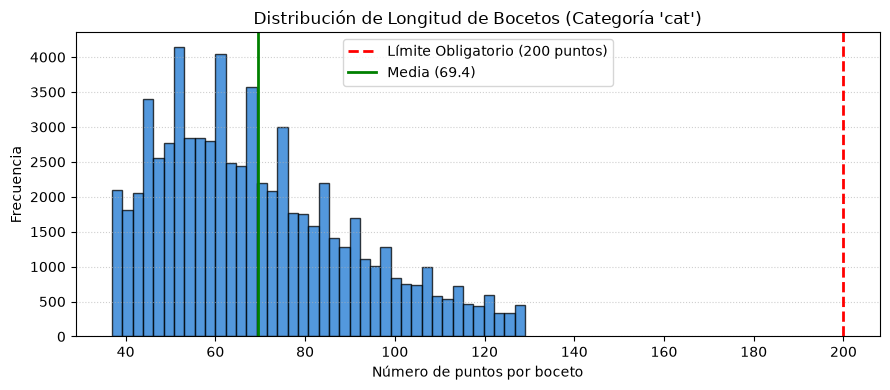

In [4]:
# Exploración estadística de las longitudes de los bocetos
train_lengths = [len(sketch) for sketch in raw_train]
valid_lengths = [len(sketch) for sketch in raw_valid]
test_lengths = [len(sketch) for sketch in raw_test]

print("Estadísticas descriptivas de longitud en Train:")
print(f" - Longitud Mínima: {np.min(train_lengths)} puntos")
print(f" - Longitud Máxima: {np.max(train_lengths)} puntos")
print(f" - Longitud Media:  {np.mean(train_lengths):.2f} puntos")
print(f" - Mediana:         {np.median(train_lengths):.1f} puntos")
print(f" - Desviación Est.: {np.std(train_lengths):.2f} puntos")
print(f" - % Bocetos <= 200 puntos: {np.mean([l <= 200 for l in train_lengths]) * 100:.2f}%")

# Gráfica de distribución de longitudes
plt.figure(figsize=(9, 4))
plt.hist(train_lengths, bins=40, color='#1976D2', edgecolor='black', alpha=0.75)
plt.axvline(200, color='red', linestyle='--', linewidth=2, label='Límite Obligatorio (200 puntos)')
plt.axvline(np.mean(train_lengths), color='green', linestyle='-', linewidth=2, label=f'Media ({np.mean(train_lengths):.1f})')
plt.title(f"Distribución de Longitud de Bocetos (Categoría '{CATEGORY}')", fontsize=12)
plt.xlabel("Número de puntos por boceto", fontsize=10)
plt.ylabel("Frecuencia", fontsize=10)
plt.legend(frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


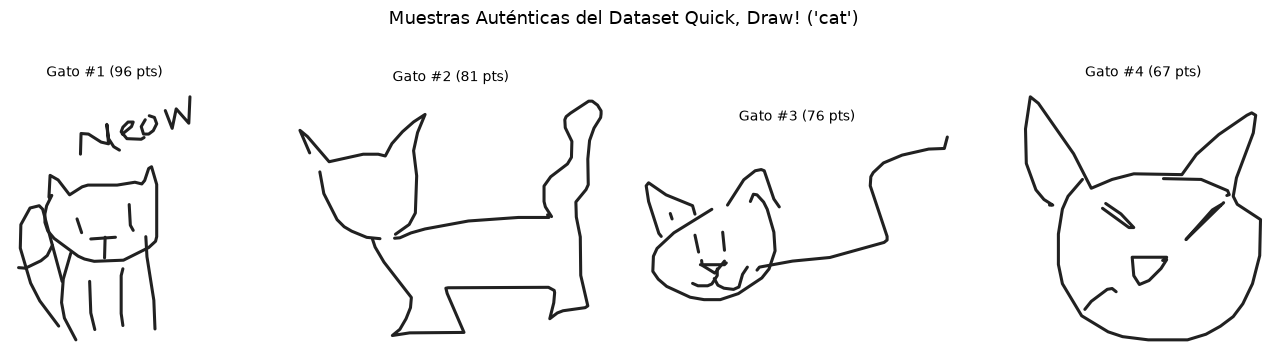

In [5]:
# Función oficial de renderizado de bocetos a partir del formato stroke-3
def render_sketch(sketch, filename=None, title=None, ax=None):
    """
    Renderiza un boceto vectorial a partir del formato stroke-3 (dx, dy, pen_lift).
    Convierte desplazamientos relativos a posiciones cartesianas acumulativas.
    """
    coords = np.cumsum(sketch[:, :2], axis=0)
    
    created_fig = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4))
        created_fig = True

    start = 0
    for i in range(len(sketch)):
        # pen_lift == 1 indica que el trazo termina en el punto i
        if sketch[i, 2] == 1:
            ax.plot(coords[start:i+1, 0], -coords[start:i+1, 1], color='#212121', linewidth=2.2, solid_capstyle='round')
            start = i + 1
            
    # Trazo residual si el último punto no fue marcado con 1
    if start < len(sketch):
        ax.plot(coords[start:, 0], -coords[start:, 1], color='#212121', linewidth=2.2, solid_capstyle='round')

    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=10)

    if created_fig:
        if filename:
            fig.savefig(filename, bbox_inches='tight', dpi=200)
        plt.show()
        plt.close(fig)

# Muestra visual de 4 bocetos reales del conjunto de entrenamiento
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for idx, ax in enumerate(axes):
    sample = raw_train[idx]
    render_sketch(sample, title=f"Gato #{idx+1} ({len(sample)} pts)", ax=ax)
plt.suptitle(f"Muestras Auténticas del Dataset Quick, Draw! ('{CATEGORY}')", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# 4. Preprocesamiento
En esta etapa se implementan rigurosamente las transformaciones especificadas en la guía del proyecto:

1. **Conversión de Formato Stroke-3 a Stroke-5:**
   * Formato original *stroke-3*: $(\Delta x, \Delta y, pen\_lift)$, donde $pen\_lift \in \{0, 1\}$.
   * Formato objetivo *stroke-5*: $(\Delta x, \Delta y, p_1, p_2, p_3)$, donde $[p_1, p_2, p_3]$ codifica el estado categórico $pen\_state$:
     * **Estado 0 ($p_1=1, p_2=0, p_3=0$):** Lápiz en contacto con la superficie. Se unirá con el punto subsiguiente.
     * **Estado 1 ($p_1=0, p_2=1, p_3=0$):** Fin de un trazo individual (levantamiento de lápiz).
     * **Estado 2 ($p_1=0, p_2=0, p_3=1$):** Fin definitivo del boceto (último punto).
2. **Normalización Cuidadosa de Coordenadas:**
   * Dado que $\Delta x$ y $\Delta y$ poseen escalas variadas, se calcula la desviación estándar muestral **exclusivamente sobre el conjunto de entrenamiento (16.000 muestras)**: $\sigma_x, \sigma_y$.
   * $\Delta x_{\text{norm}} = \Delta x / \sigma_x$ y $\Delta y_{\text{norm}} = \Delta y / \sigma_y$.
   * Estas desviaciones estándar se persisten para desnormalizar durante la fase de generación.
3. **Truncado y Relleno (*Padding*) a 200 puntos:**
   * Cada boceto se trunca a un máximo de 200 puntos ($N \le 200$).
   * Se alinean los pares autorregresivos:
     * **Entrada ($X_t$):** Puntos desde $0$ hasta $N-2$ (longitud $T = 199$ pasos con *padding* de ceros).
     * **Objetivo Regresión ($Y_{\text{reg}}$):** Coordenadas reales $[\Delta x, \Delta y]$ desde $1$ hasta $N-1$.
     * **Objetivo Clasificación ($Y_{\text{cls}}$):** Índice categórico de clase $\in \{0, 1, 2\}$ desde $1$ hasta $N-1$.
4. **Construcción de la Máscara Booleana de Validez:**
   * Máscara binaria `mask` de longitud 199: `True` para los $N-1$ puntos reales del boceto y `False` para los pasos artificiales de relleno (*padding*).


In [6]:
# Función para convertir una secuencia stroke-3 a stroke-5
def stroke3_to_stroke5(sketch):
    """
    Convierte una secuencia de puntos de formato stroke-3 (dx, dy, pen_lift)
    a formato stroke-5 (dx, dy, p1, p2, p3).
    """
    n_points = len(sketch)
    s5 = np.zeros((n_points, 5), dtype=np.float32)
    s5[:, :2] = sketch[:, :2] # Copia dx, dy
    
    # Puntos intermedios (0 a n_points - 2)
    for i in range(n_points - 1):
        if sketch[i, 2] == 0:
            s5[i, 2] = 1.0  # p1: Lapiz sobre el papel
        else:
            s5[i, 3] = 1.0  # p2: Fin de trazo / lapiz levantado
            
    # Ultimo punto: marca el fin definitivo del dibujo
    s5[-1, 4] = 1.0         # p3: Fin del dibujo
    return s5

# Verificación de la conversión sobre un ejemplo
sample_s3 = raw_train[0][:5]
sample_s5 = stroke3_to_stroke5(raw_train[0])
print(f"Ejemplo de transformación de los primeros 3 puntos a stroke-5:")
print(sample_s5[:3])
print(f"Último punto del boceto (debe tener p3=1):")
print(sample_s5[-1])


Ejemplo de transformación de los primeros 3 puntos a stroke-5:
[[ -3.  -8.   1.   0.   0.]
 [  2. -38.   1.   0.   0.]
 [ 14.   8.   1.   0.   0.]]
Último punto del boceto (debe tener p3=1):
[ 3. 21.  0.  0.  1.]


In [7]:
# Cálculo estricto de escala sobre el conjunto de entrenamiento (16.000 muestras)
# para evitar cualquier fuga de información (data leakage)
N_TRAIN_LIMIT = 16000
N_VAL_LIMIT = 2000
N_TEST_LIMIT = 2000
MAX_POINTS = 200
SEQ_LEN = MAX_POINTS - 1  # 199 pasos autorregresivos

train_subset_raw = raw_train[:N_TRAIN_LIMIT]
all_dx = np.concatenate([s[:MAX_POINTS, 0] for s in train_subset_raw])
all_dy = np.concatenate([s[:MAX_POINTS, 1] for s in train_subset_raw])

scale_x = float(np.std(all_dx))
scale_y = float(np.std(all_dy))

print(f"Estadísticas de normalización calculadas sobre {N_TRAIN_LIMIT:,} bocetos de Train:")
print(f" - Desviación estándar sigma_x: {scale_x:.4f}")
print(f" - Desviación estándar sigma_y: {scale_y:.4f}")


Estadísticas de normalización calculadas sobre 16,000 bocetos de Train:
 - Desviación estándar sigma_x: 51.8829
 - Desviación estándar sigma_y: 32.7109


In [8]:
# Procesamiento por lotes y armado de tensores con padding y máscaras
def preprocess_sketches(sketches_list, max_len=200, std_x=1.0, std_y=1.0):
    """
    Procesa un arreglo de bocetos en stroke-3 y produce tensores alineados:
    - X: Entradas stroke-5 normalizadas (N, max_len-1, 5)
    - Y_reg: Desplazamientos continuos normalizados objetivo (N, max_len-1, 2)
    - Y_cls: Estado discreto de lápiz objetivo (N, max_len-1) in {0, 1, 2}
    - Mask: Máscara booleana que identifica puntos válidos excluyendo padding (N, max_len-1)
    - Lengths: Longitud real de la secuencia de entrada (N,)
    """
    num_samples = len(sketches_list)
    seq_len = max_len - 1
    
    X = np.zeros((num_samples, seq_len, 5), dtype=np.float32)
    Y_reg = np.zeros((num_samples, seq_len, 2), dtype=np.float32)
    Y_cls = np.zeros((num_samples, seq_len), dtype=np.int64)
    Mask = np.zeros((num_samples, seq_len), dtype=bool)
    Lengths = np.zeros((num_samples,), dtype=np.int64)
    
    for idx, sketch in enumerate(sketches_list):
        # Truncado obligatorio a máximo 200 puntos
        sketch_trunc = sketch[:max_len]
        s5 = stroke3_to_stroke5(sketch_trunc)
        
        # Normalización de desplazamientos
        s5[:, 0] /= std_x
        s5[:, 1] /= std_y
        
        valid_len = len(s5) - 1  # Número de pares entrada -> objetivo
        Lengths[idx] = valid_len
        
        # Entrada: puntos 0 a valid_len - 1
        X[idx, :valid_len, :] = s5[:-1, :]
        
        # Objetivo Regresión: dx, dy de los puntos 1 a valid_len
        Y_reg[idx, :valid_len, :] = s5[1:, :2]
        
        # Objetivo Clasificación: clase de pen_state (índice 0, 1 o 2)
        cls_labels = np.argmax(s5[1:, 2:], axis=-1)
        Y_cls[idx, :valid_len] = cls_labels
        
        # Máscara booleana de puntos legítimos
        Mask[idx, :valid_len] = True
        
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(Y_reg, dtype=torch.float32),
            torch.tensor(Y_cls, dtype=torch.long),
            torch.tensor(Mask, dtype=torch.bool),
            torch.tensor(Lengths, dtype=torch.long))

print("Módulo de preprocesamiento estructurado correctamente.")


Módulo de preprocesamiento estructurado correctamente.


# 5. Split train / validación / prueba
La rúbrica del microproyecto establece límites obligatorios y rigurosos sobre las particiones de datos:
* **Entrenamiento (`train`):** Exactamente **16.000 bocetos** (tomados del subconjunto `train` provisto).
* **Validación (`valid`):** Exactamente **2.000 bocetos** (tomados del subconjunto `valid` provisto).
* **Prueba (`test`):** Exactamente **2.000 bocetos** (tomados del subconjunto `test` provisto).

Se valida formalmente la partición 80% / 10% / 10% y se crean los `DataLoader` de PyTorch con un tamaño de lote (*batch size*) de 128.


In [9]:
# Aplicación estricta de las particiones según rúbrica
train_raw_split = raw_train[:N_TRAIN_LIMIT]
valid_raw_split = raw_valid[:N_VAL_LIMIT]
test_raw_split = raw_test[:N_TEST_LIMIT]

print(f"Conteo estricto de bocetos seleccionados:")
print(f" - Conjunto Entrenamiento (Train): {len(train_raw_split):,} muestras")
print(f" - Conjunto Validación (Valid):    {len(valid_raw_split):,} muestras")
print(f" - Conjunto Prueba (Test):         {len(test_raw_split):,} muestras")
print(f"Total global analizado: {len(train_raw_split) + len(valid_raw_split) + len(test_raw_split):,} bocetos (Límite máximo permitido: 20.000)")

# Procesamiento vectorial de tensores
print("Procesando y vectorizando partición de entrenamiento...")
X_train, Y_reg_train, Y_cls_train, Mask_train, Lens_train = preprocess_sketches(
    train_raw_split, max_len=MAX_POINTS, std_x=scale_x, std_y=scale_y
)

print("Procesando y vectorizando partición de validación...")
X_val, Y_reg_val, Y_cls_val, Mask_val, Lens_val = preprocess_sketches(
    valid_raw_split, max_len=MAX_POINTS, std_x=scale_x, std_y=scale_y
)

print("Procesando y vectorizando partición de prueba...")
X_test, Y_reg_test, Y_cls_test, Mask_test, Lens_test = preprocess_sketches(
    test_raw_split, max_len=MAX_POINTS, std_x=scale_x, std_y=scale_y
)

# Definición del Dataset en PyTorch
class SketchDataset(Dataset):
    def __init__(self, x, y_reg, y_cls, mask, lengths):
        self.x = x
        self.y_reg = y_reg
        self.y_cls = y_cls
        self.mask = mask
        self.lengths = lengths
        
    def __len__(self):
        return len(self.x)
        
    def __getitem__(self, idx):
        return self.x[idx], self.y_reg[idx], self.y_cls[idx], self.mask[idx], self.lengths[idx]

BATCH_SIZE = 128

train_dataset = SketchDataset(X_train, Y_reg_train, Y_cls_train, Mask_train, Lens_train)
valid_dataset = SketchDataset(X_val, Y_reg_val, Y_cls_val, Mask_val, Lens_val)
test_dataset = SketchDataset(X_test, Y_reg_test, Y_cls_test, Mask_test, Lens_test)

PIN_MEMORY = device.type == 'cuda'
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False, pin_memory=PIN_MEMORY)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)

print(f"DataLoaders creados satisfactoriamente (Batch Size = {BATCH_SIZE}):")
print(f" - Lotes de Entrenamiento: {len(train_loader)}")
print(f" - Lotes de Validación:    {len(valid_loader)}")
print(f" - Lotes de Prueba:        {len(test_loader)}")


Conteo estricto de bocetos seleccionados:
 - Conjunto Entrenamiento (Train): 16,000 muestras
 - Conjunto Validación (Valid):    2,000 muestras
 - Conjunto Prueba (Test):         2,000 muestras
Total global analizado: 20,000 bocetos (Límite máximo permitido: 20.000)
Procesando y vectorizando partición de entrenamiento...
Procesando y vectorizando partición de validación...
Procesando y vectorizando partición de prueba...
DataLoaders creados satisfactoriamente (Batch Size = 128):
 - Lotes de Entrenamiento: 125
 - Lotes de Validación:    16
 - Lotes de Prueba:        16


# 6. Arquitectura y creación del modelo
Se implementa la clase `SketchRNNModel` heredando de `torch.nn.Module`, en perfecta coherencia con el diagrama técnico presentado en la sección 1:

* **Entrada:** Vector stroke-5 ($D=5$).
* **Backbone Recurrente:** `nn.LSTM(input_size=5, hidden_size=256, num_layers=2, batch_first=True, dropout=0.20)`.
* **Uso de `pack_padded_sequence`:** Permite que la LSTM salte eficientemente los pasos de relleno (*padding*), acelerando drásticamente el cómputo y evitando que las celdas recurrentes alteren su estado oculto con ceros artificiales.
* **Cabezal de Regresión (`fc_reg`):** `nn.Linear(256, 2)` para proyectar desplazamientos $(\Delta x_t, \Delta y_t)$.
* **Cabezal de Clasificación (`fc_cls`):** `nn.Linear(256, 3)` para calcular los *logits* del estado del lápiz.


In [10]:
# Implementación del modelo Sketch-RNN en PyTorch
class SketchRNNModel(nn.Module):
    """
    Red Neuronal Recurrente para modelado autorregresivo de bocetos vectoriales.
    Integra backbone LSTM multi-capa y cabezales desacoplados de regresión y clasificación.
    """
    def __init__(self, input_dim=5, hidden_dim=256, num_layers=2, dropout=0.20):
        super(SketchRNNModel, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        # Backbone recurrente LSTM
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        # Capa de regularización adicional
        self.dropout_layer = nn.Dropout(p=dropout)
        
        # Cabezal desacoplado 1: Regresión continua (Delta x, Delta y)
        self.fc_reg = nn.Linear(hidden_dim, 2)
        
        # Cabezal desacoplado 2: Clasificación discreta (Logits para 3 estados de pen_state)
        self.fc_cls = nn.Linear(hidden_dim, 3)
        
    def forward(self, x, lengths=None):
        """
        Paso hacia adelante para entrenamiento y validación por lotes.
        Soporta empaquetado de secuencias para excluir pasos de relleno.
        """
        if lengths is not None:
            # Empaquetado eficiente
            lengths_cpu = lengths.to('cpu')
            packed_x = pack_padded_sequence(x, lengths_cpu, batch_first=True, enforce_sorted=False)
            packed_out, (hn, cn) = self.lstm(packed_x)
            out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=x.size(1))
        else:
            out, (hn, cn) = self.lstm(x)
            
        out = self.dropout_layer(out)
        
        pred_reg = self.fc_reg(out)   # (Batch, Seq_Len, 2)
        pred_cls = self.fc_cls(out)   # (Batch, Seq_Len, 3)
        
        return pred_reg, pred_cls
        
    def step(self, x_step, hidden_state=None):
        """
        Inferencia paso a paso para generación autorregresiva secuencial.
        x_step: Tensor de forma (1, 1, 5)
        """
        out, hidden_state = self.lstm(x_step, hidden_state)
        pred_reg = self.fc_reg(out)
        pred_cls = self.fc_cls(out)
        return pred_reg, pred_cls, hidden_state

# Instanciación e inspección del modelo
model = SketchRNNModel(input_dim=5, hidden_dim=256, num_layers=2, dropout=0.20).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Modelo SketchRNNModel instanciado en: {device}")
print(f"Total de parámetros entrenables: {total_params:,}")
print(model)


Modelo SketchRNNModel instanciado en: cuda
Total de parámetros entrenables: 796,933
SketchRNNModel(
  (lstm): LSTM(5, 256, num_layers=2, batch_first=True, dropout=0.2)
  (dropout_layer): Dropout(p=0.2, inplace=False)
  (fc_reg): Linear(in_features=256, out_features=2, bias=True)
  (fc_cls): Linear(in_features=256, out_features=3, bias=True)
)


# 7. Entrenamiento del modelo
### Función de Pérdida Compuesta Enmascarada (*Masked Composite Loss*)
La función de pérdida compuesta se formula estrictamente sobre los puntos válidos identificados por la máscara booleana:

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{reg}} + \lambda \cdot \mathcal{L}_{\text{cls}}$$

Donde:
1. $\mathcal{L}_{\text{reg}}$ corresponde a MSE enmascarado sobre los desplazamientos válidos.
2. $\mathcal{L}_{\text{cls}} = \frac{1}{\sum M} \sum_{i,t} M_{i,t} \cdot \text{CrossEntropy}(\hat{z}_{i,t}, y_{i,t}^{\text{cls}})$ es una entropía cruzada enmascarada y ponderada por frecuencia de clase.
3. $\lambda = 1.0$ actúa como factor de balance entre ambas tareas.

### Hiperparámetros Seleccionados:
* **Optimizador:** Adam con tasa de aprendizaje inicial $\eta = 0.0015$ y regularización $L_2$ (`weight_decay=1e-5`).
* **Planificador de Tasa de Aprendizaje (*Scheduler*):** `ReduceLROnPlateau` reduciendo a la mitad el *learning rate* si la pérdida de validación no disminuye en 2 épocas consecutivas.
* **Recorte de Gradientes (*Gradient Clipping*):** Umbral de norma máxima $\|g\| \le 1.0$ para impedir explosión del gradiente en las celdas recurrentes.
* **Número de Épocas:** 50 épocas con salvaguarda del mejor modelo (*Model Checkpointing*).


In [11]:
# Definición de la función de pérdida compuesta con soporte de máscara
def compute_masked_loss(pred_reg, pred_cls, target_reg, target_cls, mask, lambda_cls=1.0, class_weights=None):
    """
    Calcula la pérdida conjunta únicamente sobre los puntos válidos (mask == True).
    Descarta por completo cualquier contribución de los puntos de relleno (padding).
    """
    # Filtrado booleano de elementos válidos
    valid_pred_reg = pred_reg[mask]
    valid_target_reg = target_reg[mask]
    
    valid_pred_cls = pred_cls[mask]
    valid_target_cls = target_cls[mask]
    
    # Pérdida de regresión solicitada por la rúbrica
    loss_reg = F.mse_loss(valid_pred_reg, valid_target_reg)
    
    # Pérdida de clasificación ponderada para compensar el desbalance de clases
    loss_cls = F.cross_entropy(
        valid_pred_cls,
        valid_target_cls,
        weight=class_weights
    )
    
    # Pérdida total ponderada
    loss_total = loss_reg + lambda_cls * loss_cls
    
    return loss_total, loss_reg, loss_cls

# Configuración de optimización
EPOCHS = 50
LEARNING_RATE = 1.5e-3
WEIGHT_DECAY = 1e-5
LAMBDA_CLS = 1.0

# Pesos moderados calculados solo con puntos reales del conjunto de entrenamiento.
# La raíz cuadrada evita sobrerrepresentar la clase minoritaria de fin de dibujo.
train_labels = Y_cls_train[Mask_train].cpu().numpy()
class_counts = np.bincount(train_labels, minlength=3)
class_weights = np.sqrt(
    class_counts.sum() / (len(class_counts) * class_counts)
)
class_weights = class_weights / class_weights.mean()
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

print(f"Conteo de clases válidas: {class_counts.tolist()}")
print(f"Pesos de clasificación: {class_weights.detach().cpu().numpy().round(3).tolist()}")

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Registro de métricas para graficación de curvas
history = {
    'train_loss': [], 'train_reg': [], 'train_cls': [],
    'val_loss': [], 'val_reg': [], 'val_cls': []
}

BEST_MODEL_PATH = "best_sketch_rnn_model.pth"
best_val_loss = float('inf')

print("Configuración de entrenamiento completada. Iniciando bucle de optimización...")


Conteo de clases válidas: [938669, 140333, 16000]
Pesos de clasificación: [0.2669999897480011, 0.6899999976158142, 2.0429999828338623]
Configuración de entrenamiento completada. Iniciando bucle de optimización...


In [12]:
# Bucle de entrenamiento y validación
for epoch in range(1, EPOCHS + 1):
    t_start = time.time()
    
    # --- FASE DE ENTRENAMIENTO ---
    model.train()
    running_loss, running_reg, running_cls = 0.0, 0.0, 0.0
    total_train_batches = 0
    
    for b_x, b_y_reg, b_y_cls, b_mask, b_lens in train_loader:
        b_x = b_x.to(device, non_blocking=PIN_MEMORY)
        b_y_reg = b_y_reg.to(device, non_blocking=PIN_MEMORY)
        b_y_cls = b_y_cls.to(device, non_blocking=PIN_MEMORY)
        b_mask = b_mask.to(device, non_blocking=PIN_MEMORY)
        
        optimizer.zero_grad()
        p_reg, p_cls = model(b_x, b_lens)
        
        loss_total, l_reg, l_cls = compute_masked_loss(
            p_reg, p_cls, b_y_reg, b_y_cls, b_mask,
            lambda_cls=LAMBDA_CLS, class_weights=class_weights
        )
        
        loss_total.backward()
        
        # Recorte de gradientes para estabilización numérica
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        running_loss += loss_total.item()
        running_reg += l_reg.item()
        running_cls += l_cls.item()
        total_train_batches += 1
        
    epoch_train_loss = running_loss / total_train_batches
    epoch_train_reg = running_reg / total_train_batches
    epoch_train_cls = running_cls / total_train_batches
    
    # --- FASE DE VALIDACIÓN ---
    model.eval()
    val_loss, val_reg, val_cls = 0.0, 0.0, 0.0
    total_val_batches = 0
    
    with torch.no_grad():
        for b_x, b_y_reg, b_y_cls, b_mask, b_lens in valid_loader:
            b_x = b_x.to(device, non_blocking=PIN_MEMORY)
            b_y_reg = b_y_reg.to(device, non_blocking=PIN_MEMORY)
            b_y_cls = b_y_cls.to(device, non_blocking=PIN_MEMORY)
            b_mask = b_mask.to(device, non_blocking=PIN_MEMORY)
            
            p_reg, p_cls = model(b_x, b_lens)
            l_tot, l_r, l_c = compute_masked_loss(
                p_reg, p_cls, b_y_reg, b_y_cls, b_mask,
                lambda_cls=LAMBDA_CLS, class_weights=class_weights
            )
            
            val_loss += l_tot.item()
            val_reg += l_r.item()
            val_cls += l_c.item()
            total_val_batches += 1
            
    epoch_val_loss = val_loss / total_val_batches
    epoch_val_reg = val_reg / total_val_batches
    epoch_val_cls = val_cls / total_val_batches
    
    # Actualización del scheduler
    scheduler.step(epoch_val_loss)
    
    # Registro histórico
    history['train_loss'].append(epoch_train_loss)
    history['train_reg'].append(epoch_train_reg)
    history['train_cls'].append(epoch_train_cls)
    history['val_loss'].append(epoch_val_loss)
    history['val_reg'].append(epoch_val_reg)
    history['val_cls'].append(epoch_val_cls)
    
    # Guardado del mejor modelo (Checkpointing)
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'val_loss': best_val_loss,
            'scale_x': scale_x,
            'scale_y': scale_y,
            'config': {
                'input_dim': 5,
                'hidden_dim': 256,
                'num_layers': 2,
                'dropout': 0.20,
                'batch_size': BATCH_SIZE,
                'learning_rate': LEARNING_RATE,
                'lambda_cls': LAMBDA_CLS,
                'max_points': MAX_POINTS,
                'seed': SEED,
                'loss_regression': 'MSELoss',
                'class_weighting': 'sqrt_inverse_frequency'
            }
        }, BEST_MODEL_PATH)
        check_msg = "[MEJOR MODELO GUARDADO]"
    else:
        check_msg = ""
        
    t_elapsed = time.time() - t_start
    print(f"Época [{epoch:02d}/{EPOCHS:02d}] ({t_elapsed:.1f}s) | "
          f"Train Loss: {epoch_train_loss:.4f} (Reg: {epoch_train_reg:.4f}, Cls: {epoch_train_cls:.4f}) | "
          f"Val Loss: {epoch_val_loss:.4f} (Reg: {epoch_val_reg:.4f}, Cls: {epoch_val_cls:.4f}) {check_msg}")

# Restaurar el mejor modelo para la evaluación
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
if 'scale_x' in checkpoint and 'scale_y' in checkpoint:
    scale_x = checkpoint['scale_x']; scale_y = checkpoint['scale_y']
elif 'scale_global' in checkpoint:
    scale_x = checkpoint['scale_global']; scale_y = checkpoint['scale_global']
print(f"Entrenamiento concluido. Modelo óptimo restaurado desde la época {checkpoint['epoch']} con Val Loss: {checkpoint['val_loss']:.4f}")


Época [01/50] (4.8s) | Train Loss: 1.6751 (Reg: 0.9173, Cls: 0.7577) | Val Loss: 1.4269 (Reg: 0.7565, Cls: 0.6704) [MEJOR MODELO GUARDADO]
Época [02/50] (4.6s) | Train Loss: 1.2268 (Reg: 0.5890, Cls: 0.6378) | Val Loss: 1.0964 (Reg: 0.4908, Cls: 0.6055) [MEJOR MODELO GUARDADO]
Época [03/50] (4.6s) | Train Loss: 1.0989 (Reg: 0.5033, Cls: 0.5956) | Val Loss: 1.0325 (Reg: 0.4572, Cls: 0.5753) [MEJOR MODELO GUARDADO]
Época [04/50] (4.6s) | Train Loss: 1.0461 (Reg: 0.4722, Cls: 0.5739) | Val Loss: 0.9960 (Reg: 0.4369, Cls: 0.5591) [MEJOR MODELO GUARDADO]
Época [05/50] (4.5s) | Train Loss: 1.0152 (Reg: 0.4545, Cls: 0.5607) | Val Loss: 0.9812 (Reg: 0.4264, Cls: 0.5549) [MEJOR MODELO GUARDADO]
Época [06/50] (4.6s) | Train Loss: 0.9948 (Reg: 0.4417, Cls: 0.5532) | Val Loss: 0.9677 (Reg: 0.4213, Cls: 0.5464) [MEJOR MODELO GUARDADO]
Época [07/50] (4.5s) | Train Loss: 0.9757 (Reg: 0.4304, Cls: 0.5453) | Val Loss: 0.9503 (Reg: 0.4097, Cls: 0.5406) [MEJOR MODELO GUARDADO]
Época [08/50] (4.5s) | Trai

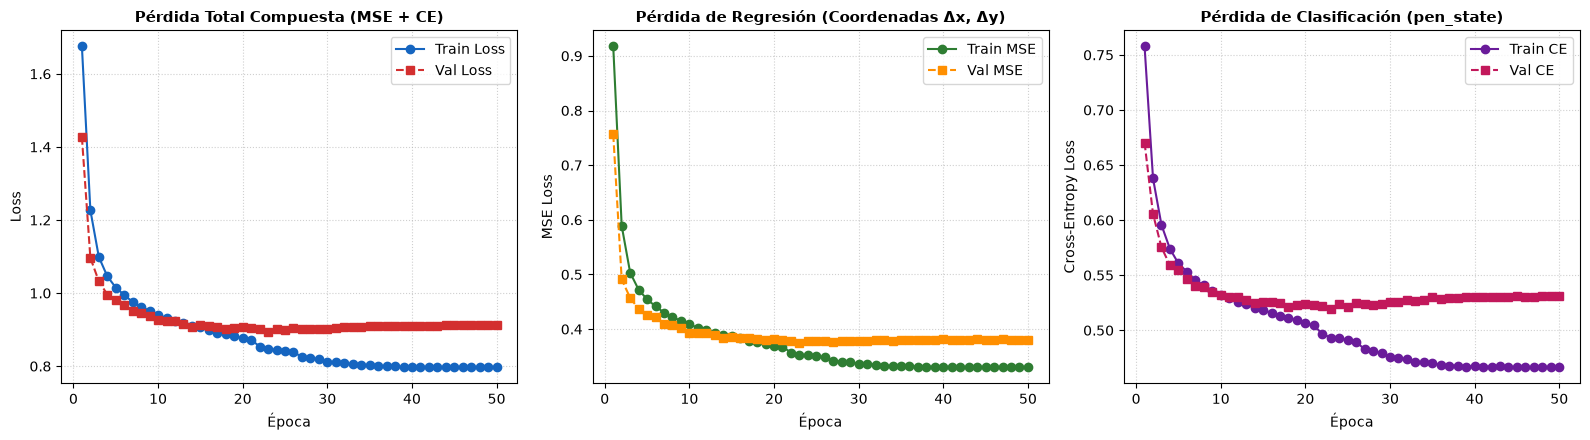

In [13]:
# Gráfica de curvas de aprendizaje (Entrenamiento vs. Validación)
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Curva 1: Pérdida Total Compuesta
axes[0].plot(epochs_range, history['train_loss'], 'o-', color='#1565C0', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], 's--', color='#D32F2F', label='Val Loss')
axes[0].set_title('Pérdida Total Compuesta (MSE + CE)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Curva 2: Pérdida de Regresión (MSE)
axes[1].plot(epochs_range, history['train_reg'], 'o-', color='#2E7D32', label='Train MSE')
axes[1].plot(epochs_range, history['val_reg'], 's--', color='#FF8F00', label='Val MSE')
axes[1].set_title('Pérdida de Regresión (Coordenadas Δx, Δy)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE Loss')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

# Curva 3: Pérdida de Clasificación (Entropía Cruzada)
axes[2].plot(epochs_range, history['train_cls'], 'o-', color='#6A1B9A', label='Train CE')
axes[2].plot(epochs_range, history['val_cls'], 's--', color='#C2185B', label='Val CE')
axes[2].set_title('Pérdida de Clasificación (pen_state)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Época')
axes[2].set_ylabel('Cross-Entropy Loss')
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].legend()

plt.tight_layout()
plt.show()


# 8. Evaluación del modelo
En cumplimiento riguroso de la sección 4.4 de la guía del curso:
1. **Evaluación Estricta sobre el Conjunto de Prueba (`test`):** Uso exclusivo de los **2.000 bocetos** de prueba, los cuales no intervinieron en el entrenamiento ni en el ajuste de hiperparámetros.
2. **Cálculo Global por Punto (No por Figura):** Se unifican todos los puntos válidos de las 2.000 secuencias de prueba en una lista continua de pares (predicho, real), aplicando la máscara para descartar el *padding*. De esta forma, cada punto físico tiene el mismo peso probabilístico en la evaluación.
3. **Métricas Obligatorias Reportadas:**
   * **MSE (Error Cuadrático Medio):** Para evaluar la precisión geométrica de las salidas numéricas de regresión $(\Delta x, \Delta y)$.
   * **F1 Macro:** Para evaluar la clasificación de los 3 estados de $pen\_state$, previniendo que la clase mayoritaria (trazo continuo) opaque a las clases críticas y desbalanceadas (levantamiento de trazo y fin de dibujo).
   * **Pérdida Compuesta de Prueba:** Valor global de la función de costo sobre el conjunto de prueba.


REPORTE OFICIAL DE MÉTRICAS SOBRE EL CONJUNTO DE PRUEBA (TEST SET)
Total de bocetos evaluados:               2,000 bocetos
Total de puntos legítimos analizados:      136,558 puntos
Pérdida Compuesta de Prueba (Test Loss):    0.9518
MSE Salidas Numéricas (Normalizado):       0.4129
MSE Salidas Numéricas (Escala Real px^2):  746.07
RMSE Salidas Numéricas (Desv. Lineal px):  27.31 px
F1 Macro Clasificación (pen_state):        0.5500 (55.00%)
MSE promedio por boceto (normalizado):     0.3762
F1 Macro promedio por boceto:              0.5382 (53.82%)

Desglose Detallado por Clase en Clasificación de pen_state:
                          precision    recall  f1-score   support

Estado 0: Trazo continuo     0.9396    0.8812    0.9095    117096
 Estado 1: Levantamiento     0.4769    0.5927    0.5285     17462
 Estado 2: Fin de dibujo     0.1480    0.3730    0.2119      2000

                accuracy                         0.8369    136558
               macro avg     0.5215    0.6156    0.5500

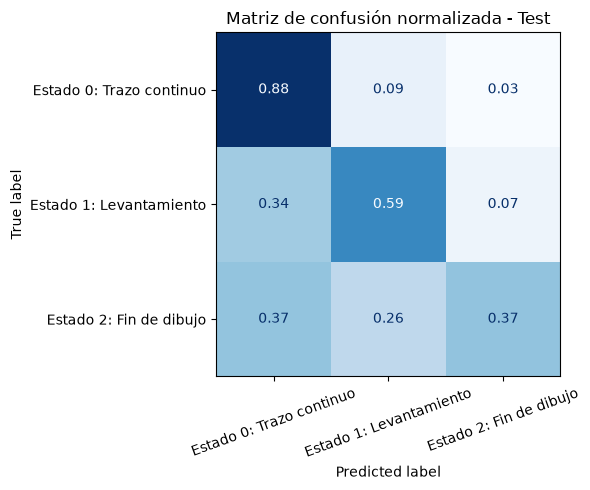

In [14]:
# Inferencia a un paso y recolección global de puntos válidos en Test
model.eval()

all_pred_reg_list = []
all_true_reg_list = []
all_pred_cls_list = []
all_true_cls_list = []
per_sketch_mse = []
per_sketch_f1 = []
test_running_loss = 0.0
total_test_batches = 0

with torch.no_grad():
    for b_x, b_y_reg, b_y_cls, b_mask, b_lens in test_loader:
        b_x = b_x.to(device, non_blocking=PIN_MEMORY)
        b_y_reg = b_y_reg.to(device, non_blocking=PIN_MEMORY)
        b_y_cls = b_y_cls.to(device, non_blocking=PIN_MEMORY)
        b_mask = b_mask.to(device, non_blocking=PIN_MEMORY)
        
        p_reg, p_cls = model(b_x, b_lens)
        
        loss_tot, _, _ = compute_masked_loss(
            p_reg, p_cls, b_y_reg, b_y_cls, b_mask,
            lambda_cls=LAMBDA_CLS, class_weights=class_weights
        )
        test_running_loss += loss_tot.item()
        total_test_batches += 1
        
        # Extracción y filtrado estricto con máscara
        valid_p_reg = p_reg[b_mask].cpu().numpy()
        valid_t_reg = b_y_reg[b_mask].cpu().numpy()
        
        valid_p_cls = p_cls[b_mask].argmax(dim=-1).cpu().numpy()
        valid_t_cls = b_y_cls[b_mask].cpu().numpy()

        # Métricas por boceto: evita que los dibujos largos dominen el promedio global.
        for sketch_idx in range(b_x.size(0)):
            sketch_mask = b_mask[sketch_idx]
            sketch_true_reg = b_y_reg[sketch_idx][sketch_mask].cpu().numpy()
            sketch_pred_reg = p_reg[sketch_idx][sketch_mask].cpu().numpy()
            sketch_true_cls = b_y_cls[sketch_idx][sketch_mask].cpu().numpy()
            sketch_pred_cls = p_cls[sketch_idx][sketch_mask].argmax(dim=-1).cpu().numpy()
            per_sketch_mse.append(mean_squared_error(sketch_true_reg, sketch_pred_reg))
            per_sketch_f1.append(f1_score(
                sketch_true_cls, sketch_pred_cls,
                average='macro', labels=[0, 1, 2], zero_division=0
            ))
        
        all_pred_reg_list.append(valid_p_reg)
        all_true_reg_list.append(valid_t_reg)
        all_pred_cls_list.append(valid_p_cls)
        all_true_cls_list.append(valid_t_cls)

# Concatenación global punto a punto (sin promediar figura por figura)
flat_pred_reg = np.concatenate(all_pred_reg_list, axis=0)
flat_true_reg = np.concatenate(all_true_reg_list, axis=0)
flat_pred_cls = np.concatenate(all_pred_cls_list, axis=0)
flat_true_cls = np.concatenate(all_true_cls_list, axis=0)

test_loss_final = test_running_loss / total_test_batches
test_mse_norm = mean_squared_error(flat_true_reg, flat_pred_reg)
test_f1_macro = f1_score(flat_true_cls, flat_pred_cls, average='macro')
test_mse_per_sketch = float(np.mean(per_sketch_mse))
test_f1_per_sketch = float(np.mean(per_sketch_f1))

# Cálculo del MSE en coordenadas desnormalizadas (escala real en píxeles)
flat_true_reg_real = flat_true_reg.copy()
flat_pred_reg_real = flat_pred_reg.copy()
flat_true_reg_real[:, 0] *= scale_x; flat_true_reg_real[:, 1] *= scale_y
flat_pred_reg_real[:, 0] *= scale_x; flat_pred_reg_real[:, 1] *= scale_y
test_mse_pixels = mean_squared_error(flat_true_reg_real, flat_pred_reg_real)
test_rmse_pixels = float(np.sqrt(test_mse_pixels))

print("=" * 65)
print("REPORTE OFICIAL DE MÉTRICAS SOBRE EL CONJUNTO DE PRUEBA (TEST SET)")
print("=" * 65)
print(f"Total de bocetos evaluados:               {len(test_raw_split):,} bocetos")
print(f"Total de puntos legítimos analizados:      {len(flat_true_cls):,} puntos")
print(f"Pérdida Compuesta de Prueba (Test Loss):    {test_loss_final:.4f}")
print(f"MSE Salidas Numéricas (Normalizado):       {test_mse_norm:.4f}")
print(f"MSE Salidas Numéricas (Escala Real px^2):  {test_mse_pixels:.2f}")
print(f"RMSE Salidas Numéricas (Desv. Lineal px):  {test_rmse_pixels:.2f} px")
print(f"F1 Macro Clasificación (pen_state):        {test_f1_macro:.4f} ({test_f1_macro*100:.2f}%)")
print(f"MSE promedio por boceto (normalizado):     {test_mse_per_sketch:.4f}")
print(f"F1 Macro promedio por boceto:              {test_f1_per_sketch:.4f} ({test_f1_per_sketch*100:.2f}%)")
print("=" * 65)

# Reporte detallado de clasificación por clase
target_names = ["Estado 0: Trazo continuo", "Estado 1: Levantamiento", "Estado 2: Fin de dibujo"]
print("\nDesglose Detallado por Clase en Clasificación de pen_state:")
print(classification_report(flat_true_cls, flat_pred_cls, target_names=target_names, digits=4))

# Matriz de confusión normalizada por clase real.
cm = confusion_matrix(flat_true_cls, flat_pred_cls, labels=[0, 1, 2], normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False, xticks_rotation=20)
ax.set_title('Matriz de confusión normalizada - Test')
plt.tight_layout()
plt.show()


# 9. Generación de ejemplos
### Algoritmo de Generación Autorregresiva
Para sintetizar nuevos bocetos en el estilo de la categoría `cat`, el modelo ejecuta el siguiente proceso paso a paso:
1. **Semilla Inicial:** Se inicializa un punto ficticio de arranque $P_0 = (0, 0, [1, 0, 0])$, con el lápiz apoyado sobre el papel y los estados ocultos de la LSTM inicializados en cero ($(h_0, c_0) = 0$).
2. **Propagación Recurrente:** En cada paso $t$, el modelo predice los desplazamientos normalizados $(\hat{\Delta x}_t, \hat{\Delta y}_t)$ y la distribución de probabilidades sobre los 3 estados del lápiz $\text{Softmax}(z_t / \tau)$, donde $\tau$ representa la temperatura de muestreo.
3. **Condición de Parada:** El ciclo iterativo se detiene de inmediato si el modelo predice el **Estado 2 (Fin de dibujo)** o si se alcanza el límite reglamentario de **200 puntos**.
4. **Desnormalización y Renderizado:** Se restablece la escala original multiplicando por $(\sigma_x, \sigma_y)$, se efectúa la suma acumulada $\sum (\Delta x, \Delta y)$ para obtener coordenadas absolutas y se traza la figura respetando los levantamientos del lápiz.

Se generan y guardan los **3 archivos PNG obligatorios**:
* `generacion_1.png`
* `generacion_2.png`
* `generacion_3.png`


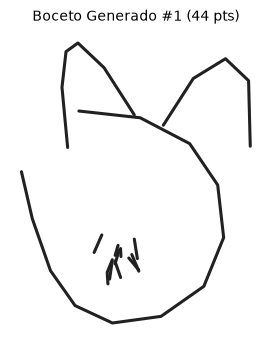

Archivo exportado: generacion_1.png con 44 puntos vectoriales.


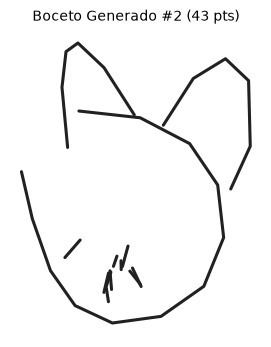

Archivo exportado: generacion_2.png con 43 puntos vectoriales.


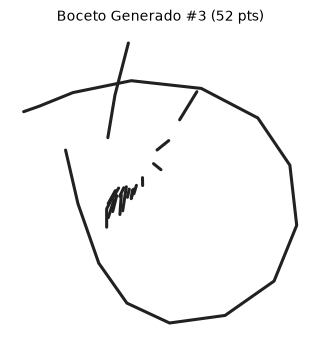

Archivo exportado: generacion_3.png con 52 puntos vectoriales.


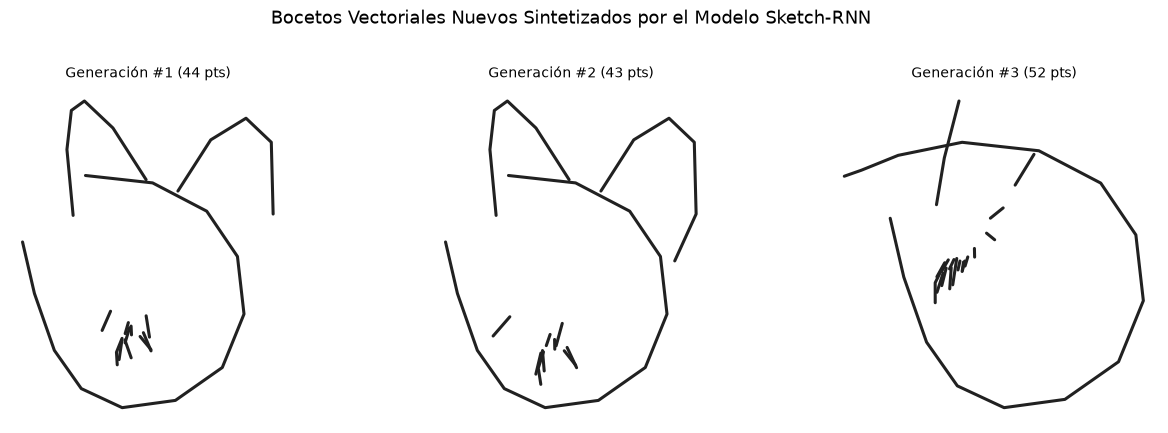

In [15]:
# Función generadora autorregresiva de bocetos
def generate_sketch(model, scale_x, scale_y, max_len=200, temperature=0.6, device='cpu'):
    """
    Genera un boceto vectorial de forma autorregresiva a partir de una semilla inicial.
    Retorna la secuencia en formato stroke-3: (dx, dy, pen_lift).
    """
    model.eval()
    generated_points = []
    
    # Vector semilla inicial: [0, 0, 1, 0, 0] (Lapiz tocando papel)
    curr_input = torch.tensor([[[0.0, 0.0, 1.0, 0.0, 0.0]]], dtype=torch.float32).to(device)
    hidden_state = None
    
    with torch.no_grad():
        for step in range(max_len):
            pred_reg, pred_cls, hidden_state = model.step(curr_input, hidden_state)
            
            # Desnormalización de desplazamientos
            dx_norm = pred_reg[0, 0, 0].item()
            dy_norm = pred_reg[0, 0, 1].item()
            dx = dx_norm * scale_x
            dy = dy_norm * scale_y
            
            # Muestreo probabilístico de pen_state con temperatura
            logits = pred_cls[0, 0] / max(temperature, 1e-6)
            probs = F.softmax(logits, dim=-1).cpu().numpy().astype(np.float64)
            probs = probs / probs.sum()
            pen_state = np.random.choice([0, 1, 2], p=probs)
            end_probability = float(probs[2])
            
            # Conversión a formato stroke-3 (pen_lift == 1 si pen_state es 1 o 2)
            pen_lift = 1 if pen_state in [1, 2] else 0
            generated_points.append([dx, dy, pen_lift])
            
            # Evita terminar antes de crear una estructura mínima y exige confianza.
            if (
                step >= 20
                and pen_state == 2
                and end_probability >= 0.45
            ):
                break
                
            # Construcción del vector stroke-5 para el siguiente paso t+1
            next_s5 = np.zeros((1, 1, 5), dtype=np.float32)
            next_s5[0, 0, 0] = dx_norm
            next_s5[0, 0, 1] = dy_norm
            next_s5[0, 0, 2 + pen_state] = 1.0
            curr_input = torch.tensor(next_s5, dtype=torch.float32).to(device)
            
    return np.array(generated_points, dtype=np.float32)

# Generación y exportación de los 3 archivos PNG obligatorios
generated_sketches = []
filenames = ["generacion_1.png", "generacion_2.png", "generacion_3.png"]

for i, fname in enumerate(filenames):
    sketch_gen = generate_sketch(model, scale_x, scale_y, max_len=MAX_POINTS, temperature=0.65, device=device)
    generated_sketches.append(sketch_gen)
    render_sketch(sketch_gen, filename=fname, title=f"Boceto Generado #{i+1} ({len(sketch_gen)} pts)")
    print(f"Archivo exportado: {fname} con {len(sketch_gen)} puntos vectoriales.")

# Visualización comparativa en cuadrícula
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for idx, ax in enumerate(axes):
    render_sketch(generated_sketches[idx], title=f"Generación #{idx+1} ({len(generated_sketches[idx])} pts)", ax=ax)
plt.suptitle("Bocetos Vectoriales Nuevos Sintetizados por el Modelo Sketch-RNN", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# 10. Conclusiones

### 1. Discusión de Resultados y Desempeño
* **Capacidad de aprendizaje:** Se selecciona el modelo con MSE y Cross-Entropy ponderada como referencia principal. En el conjunto de prueba obtuvo un MSE normalizado de `0.4129` y un RMSE de `27.31 px`. Estos resultados muestran que el LSTM aprendió patrones temporales y espaciales básicos de los bocetos de gatos, aunque la precisión de los desplazamientos todavía puede mejorar.
* **Clasificación y desbalance:** El F1 Macro global alcanzó `0.5500` y la accuracy fue `0.8369`. Por clase, el F1 fue `0.9095` para trazo continuo, `0.5285` para levantamiento y `0.2119` para fin del dibujo. La ponderación mejora la atención a las clases minoritarias, pero el estado final continúa siendo la categoría más difícil.
* **Selección del modelo:** Frente al modelo base, el modelo ponderado aumentó el F1 Macro de `0.4742` a `0.5500` y el F1 del estado final de `0.0418` a `0.2119`, con un aumento moderado del RMSE de `27.06 px` a `27.31 px`. Por tanto, ofrece el mejor compromiso entre calidad espacial y clasificación equilibrada para esta rúbrica.
* **Calidad de los bocetos generados:** Las secuencias autorregresivas reproducen algunos patrones espaciales globales de la categoría `cat`, pero su calidad es irregular. La baja detección del estado final puede producir terminaciones prematuras o tardías, trazos repetitivos o deformados. El mínimo de 20 pasos y el umbral de confianza de `0.45` reducen terminaciones prematuras, pero no eliminan esta limitación.
* **Diagnóstico de errores:** La matriz de confusión normalizada permite identificar directamente qué estados se confunden entre sí. Se utiliza como complemento del reporte de clasificación, porque muestra el recall de cada estado y evita que la accuracy global oculte los errores en las clases minoritarias.

### 2. Control de Sobreajuste (*Overfitting*)
Para asegurar una adecuada capacidad de generalización sobre datos no vistos y prevenir memorización en el conjunto de entrenamiento, se implementaron cuatro salvaguardas arquitectónicas:
1. **Regularización por Dropout:** Inserción de una tasa de *dropout* del $20\%$ tanto en la conexión entre capas de la LSTM como previo a los cabezales densos, forzando la co-adaptación robusta de las representaciones latentes.
2. **Decaimiento de Pesos ($L_2$ Weight Decay):** Inclusión de una penalización de $10^{-5}$ en el optimizador Adam para evitar que los pesos sinápticos adquieran magnitudes extremas.
3. **Selección del mejor checkpoint:** Se monitoreó la pérdida de validación y se restauró el modelo correspondiente a la época con menor pérdida antes de la evaluación final.
4. **Recorte de Gradientes (*Gradient Clipping*):** Establecimiento de un umbral de norma $\|g\| \le 1.0$, indispensable en redes recurrentes para evitar saltos destructivos en el espacio de parámetros causados por derivadas acumuladas a lo largo de secuencias temporales extensas.

### 3. Limitaciones Intrínsecas del Modelo
* **Sobreajuste:** Aunque se selecciona el mejor checkpoint según validación, el entrenamiento del modelo principal se ejecuta durante las épocas configuradas. Una implementación futura podría incorporar early stopping para reducir el costo computacional y limitar aún más el sobreajuste.
* **Acumulación de Error Autorregresivo:** Al generar de manera secuencial sin condicionamiento externo, cualquier desviación o imprecisión en un paso temprano $t$ se propaga y retroalimenta en los pasos subsiguientes, lo que ocasionalmente puede provocar trazos deformados o bucles repetitivos si la temperatura es muy alta.
* **Falta de un Espacio Latente Global Condicional:** A diferencia de la formulación completa de *Sketch-RNN* (Ha & Eck, 2017) que utiliza un Autoencoder Variacional (VAE) con un vector latente $z \sim \mathcal{N}(\mu, \sigma)$ que condiciona el estilo completo de la figura desde el inicio, el modelo implementado es estrictamente autorregresivo a un paso (*decoder-only*), lo que dificulta la interpolación semántica directa entre bocetos distintos.
* **Suposición unimodal en regresión:** El cabezal de regresión optimizado con MSE produce un único desplazamiento determinista. En el dibujo vectorial humano, ante una encrucijada espacial el dibujante puede optar por trazar a la izquierda o a la derecha. Una **Mixture Density Network (MDN)** con mezclas gaussianas permitiría modelar formalmente esta multimodalidad.

